# Fig 2: the benchmark grid

This notebook draws the paper's Fig 2 from pre-computed numbers only. It reads one file,
`figures/fig2_benchmark/grid_values.csv` from the figshare item, and draws it with the plot
modules in `figures/`. Those modules are copies of the figure package's scripts. Nothing is
recomputed: each bar is a value in the CSV, and the script refuses to draw a bar that differs from
it.

What the grid shows:
* **Seven endpoints** (rows), in four families: temporal consistency, latent structure,
  cross-modal transfer and rare-type resolution. `README.md` defines each one.
* **Five datasets** (columns): HC, HO, DR and MN, then PFC. For PFC, every method was trained on
  the same 8,000 + 8,000 nuclei, the largest size all seven methods reached, and is scored on all
  of them.
* **Ours** is the release configuration (SDE path-KL, β = 1e-4). On the four datasets it is the
  mean of seeds 0, 1 and 2. On PFC it is the mean of seeds 22, 44 and 88.
* **Competitors**, four datasets: scMultiNODE (5 seeds; 4 on DR), uniPort (5 seeds), and one fit
  each of SCOTv1, SCOTv2, Pamona and UnionCom. On HO, Pamona and UnionCom are scMultiNODE's
  published latents, which its authors fitted on all cells; they are scored as every other fit.
  **PFC:** one fit per competitor.

Read with care:
* An empty bar is a cell that was not scored. DR `rna_rare_sil` is empty for every method: the
  three rarest RNA types hold 1, 1 and 2 cells.
* DR `lta_type` is 1.000 for every method, a tie.
* HO's cell-type annotation is a coarsening of the time point, so its type-based endpoints are
  circular with time.
* The PFC benchmark is in-sample: it is scored on training nuclei of the whole-donor split.
* Values are not comparable across datasets. The ranks are.

The per-fit numbers behind each bar are in `benchmark/scores.csv` of the figshare item.
`score.py` recomputes them from the embeddings.

In [1]:
import os
import sys
import tempfile
from pathlib import Path

import matplotlib
import pandas as pd
from IPython.display import Image, display

# Jupyter runs a notebook with its own folder (benchmark/) as the working directory.
BENCHMARK = Path.cwd()
if not (BENCHMARK / "figures" / "plot_pfc_grid.py").is_file():
    raise RuntimeError("run this notebook from the repository's benchmark/ folder")
# The figshare folder: $MTVAE_DATA, else ../figshare next to the repository.
DATA = Path(os.environ.get("MTVAE_DATA", BENCHMARK.parent.parent / "figshare"))
FIG_DATA = DATA / "figures" / "fig2_benchmark"
missing = [name for name in ["grid_values.csv"] if not (FIG_DATA / name).is_file()]
if missing:
    raise FileNotFoundError(f"figures/fig2_benchmark/ lacks {missing}: set MTVAE_DATA "
                            "to the unzipped figshare folder")
# The figure files go to $MTVAE_FIG_OUT, else a new temporary folder.
OUT = Path(os.environ.get("MTVAE_FIG_OUT") or tempfile.mkdtemp(prefix="fig2_benchmark_"))
sys.path.insert(0, str(BENCHMARK / "figures"))
print("matplotlib", matplotlib.__version__, "| reading", "figures/fig2_benchmark/:", ", ".join(["grid_values.csv"]))

matplotlib 3.11.1 | reading figures/fig2_benchmark/: grid_values.csv


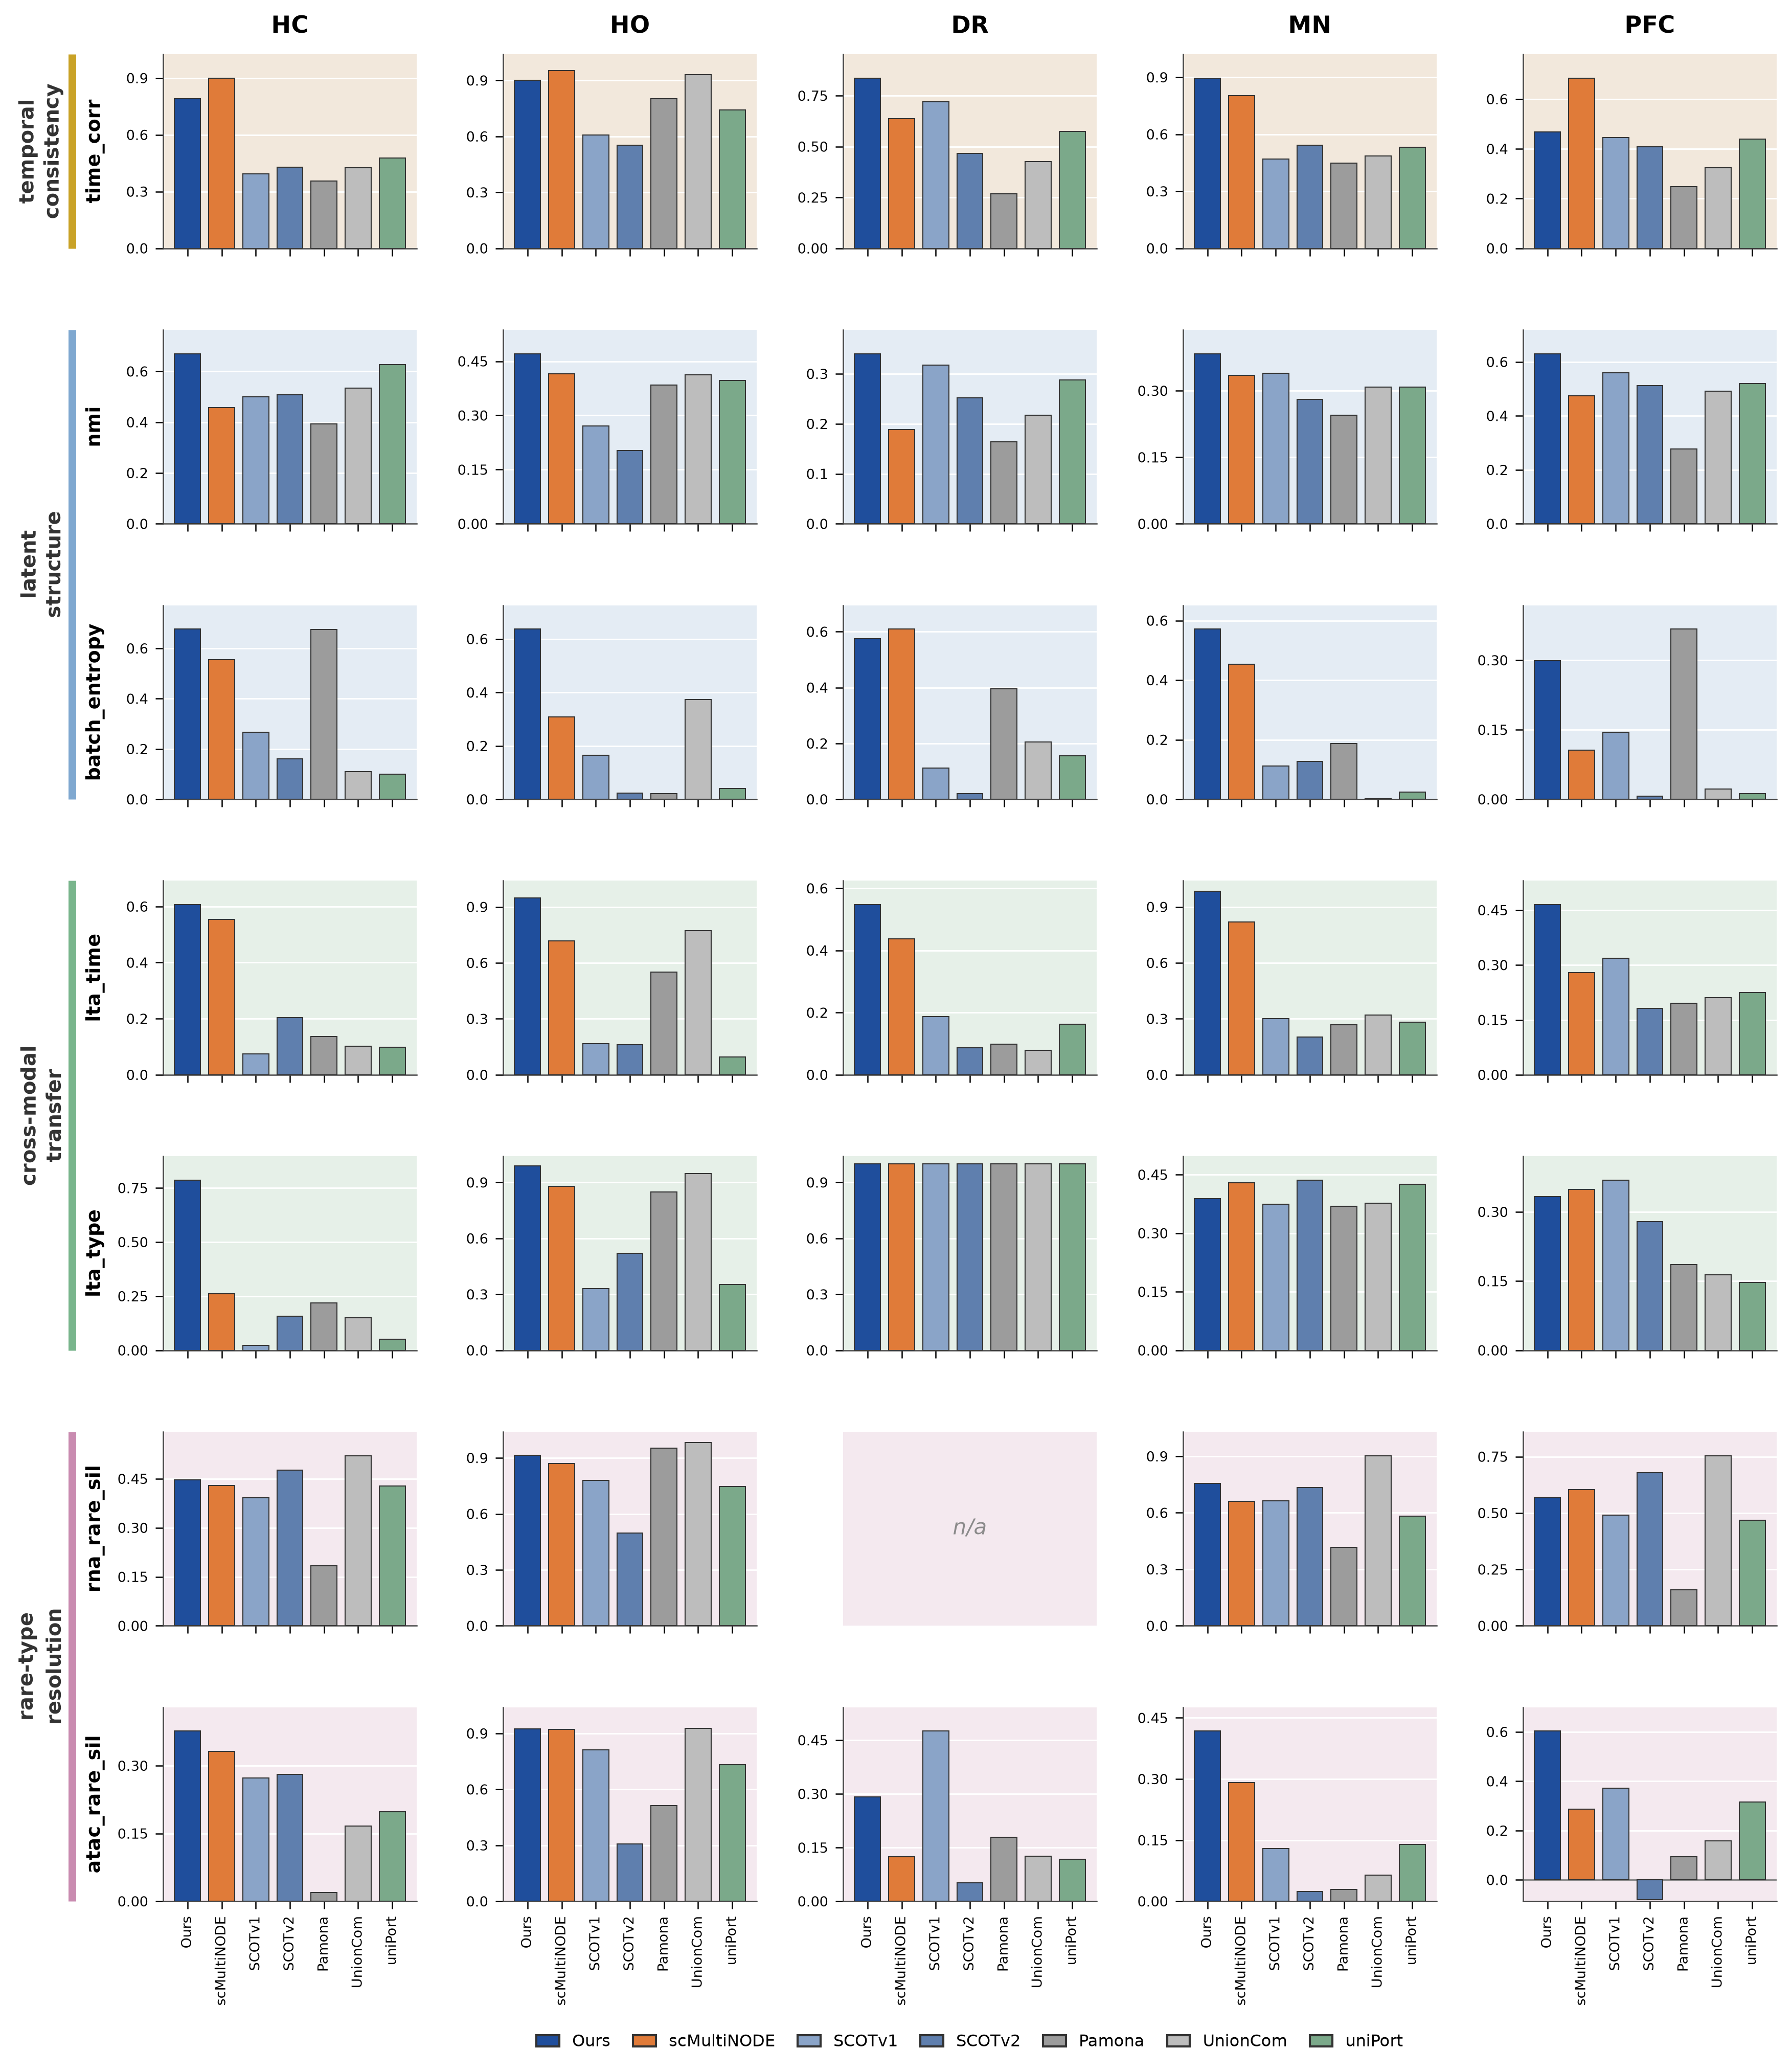

In [2]:
import plot_pfc_grid  # Fig 2's package script; it draws through plot_pfc_benchmark.grid_figure

pb = plot_pfc_grid.pb
pb.HERE = FIG_DATA  # the module reads grid_values.csv from HERE: point it at the figshare folder
pb.grid_figure(OUT)
png = OUT / "fourds_benchmark_grid_trimmed_pfc.png"
display(Image(filename=str(png)))